# 🔧 INLG 2026 — Evaluation Repair Clinic

In each scenario, **repair the evaluation**, not the generated model output.

- **Scenario A: Constructs:** Which of three legal simplifications should an evaluation reward? What happens when some information cannot be traded away for brevity?
- **Scenario B: Evidence → Claims:** Does the selection of evaluations in a **real Claude Sonnet 4.6 system card** justify broad claims about its capabilities?
- **Scenario C: Judges → Aggregation:** What happens when the **same model** rates the same arguments under **six prompted perspectives**?

### Our five-layer evaluation lens

**Constructs**: What are we trying to measure?  
**Evidence**: What information supports it?  
**Judges**: Who or what makes the judgment?  
**Aggregation**: What gets combined or lost?  
**Claims**: What can we responsibly conclude?

For each scenario, your goal is to **repair the evaluation protocol**, not rewrite the generated answer.

---
## A) Which simplification should win?

**Source notice:** “Any person who wishes to contest the decision communicated in this notice may seek a review of that decision by submitting an appeal in accordance with the applicable procedural requirements.

The appeal must be submitted within a period of fourteen (14) days, calculated from the date on which the recipient receives the decision. For the purposes of this procedure, an appeal must be made in writing and directed to the authority designated as responsible for receiving appeals.

Recipients are advised that the specified time limit applies to the submission of the appeal and should therefore take care to ensure that the applicable deadline is observed. Appeals submitted after the expiry of the fourteen-day period may not be considered by the designated authority.

Accordingly, anyone intending to challenge the decision should ensure that both the prescribed time limit and the requirement for written submission to the designated authority are observed.”

Consider three outputs:

**A: Very short:** “If you disagree, request a review.”

**B: Formally complete:** “An appeal must be lodged by written submission to the designated authority no later than fourteen days following receipt of the decision. Appeals submitted beyond the prescribed period may be deemed inadmissible.”

**C: Plain language:** “If you disagree with this decision, you can appeal. Send your appeal in writing to the designated authority within 14 days of receiving the decision.”

**Before running the code:** Which one would you pick if you were told the goal is *good legal simplification*? What criteria are indispensable?

**Your task:** Run the first cell to see how a brevity-only evaluation ranks them. Then edit the **weights** and **hard requirements** in the second cell. See whether the winner changes.

In [ ]:
# @title A1) Inspect three candidates and a brevity-only ranking
import pandas as pd

ORIGINAL_NOTICE = """
Any person who wishes to contest the decision communicated in this notice may seek a review of that decision by submitting an appeal in accordance with the applicable procedural requirements.

The appeal must be submitted within a period of fourteen (14) days, calculated from the date on which the recipient receives the decision. For the purposes of this procedure, an appeal must be made in writing and directed to the authority designated as responsible for receiving appeals.

Recipients are advised that the specified time limit applies to the submission of the appeal and should therefore take care to ensure that the applicable deadline is observed. Appeals submitted after the expiry of the fourteen-day period may not be considered by the designated authority.

Accordingly, anyone intending to challenge the decision should ensure that both the prescribed time limit and the requirement for written submission to the designated authority are observed.
"""

In [ ]:
CANDIDATES = {
    "A: very short": "If you disagree, request a review.",
    "B: formally complete": """An appeal must be lodged by written submission
    to the designated authority no later than fourteen days following receipt
    of the decision. Appeals submitted beyond the prescribed period may be
    deemed inadmissible.""",
    "C: plain language": """If you disagree with this decision, you can appeal.
    Send your appeal in writing to the designated authority within 14 days of
    receiving the decision.""",
}


You can experiment down here with different items that each response preserves. Do you argee with the labels that are already here? Are there any factors that are missing from this list of suggested conditions/checks?

In [ ]:
ACCESSIBILITY = {"A: very short": 5, "B: formally complete": 1, "C: plain language": 4}
PRESERVES = {
    "A: very short": {"appeal_option"},
    "B: formally complete": {"appeal_option", "deadline", "written", "authority", "late_consequence"},
    "C: plain language": {"appeal_option", "deadline", "written", "authority"},
}


In [ ]:
summary_A = pd.DataFrame([
    {"candidate": name, "words": len(text.split()),
     "information items kept (of 5)": len(PRESERVES[name]),
     "illustrative accessibility (1–5)": ACCESSIBILITY[name]}
    for name, text in CANDIDATES.items()
])

print("Original notice length:", len(ORIGINAL_NOTICE.split()), "words")
summary_A.sort_values("words")

In [ ]:
print("BREVITY-ONLY WINNER:", summary_A.sort_values("words").iloc[0]["candidate"])

Does this establish the best *legal simplification*? What construct is missing?

In [ ]:
# @title A2) Change the evaluation protocol — do you change the winner?
# ✏️ Adjust any of these weights; they need not sum to 1 (we normalize them).
WEIGHTS = {"brevity": 0.40, "accessibility": 0.40, "information": 0.20}

# ✏️ Choose what a usable legal simplification MUST preserve.
ALL_INFORMATION = {"appeal_option", "deadline", "written", "authority", "late_consequence"}
MUST_PRESERVE = {"appeal_option", "deadline", "written", "authority"}


In [ ]:
words_by_candidate = {name: len(text.split()) for name, text in CANDIDATES.items()}
shortest, longest = min(words_by_candidate.values()), max(words_by_candidate.values())
w_total = sum(WEIGHTS.values())
results_A = []

In [ ]:
for name, count in words_by_candidate.items():
    brevity = 5 if shortest == longest else 5 - 4 * (count - shortest) / (longest - shortest)
    accessibility = ACCESSIBILITY[name]
    information = 5 * len(PRESERVES[name]) / len(ALL_INFORMATION)
    overall = sum(WEIGHTS[k] * s for k, s in {
        "brevity": brevity, "accessibility": accessibility, "information": information
    }.items()) / w_total
    missing = MUST_PRESERVE - PRESERVES[name]
    results_A.append({
        "candidate": name,
        "brevity": brevity,
        "accessibility": accessibility,
        "information": information,
        "weighted score": round(overall, 2),
        "meets hard requirements": not missing,
        "missing required items": ", ".join(sorted(missing)) or "—",
        })



In [ ]:
ranked_A = pd.DataFrame(results_A).sort_values("weighted score", ascending=False)
ranked_A

In [ ]:
print("Highest weighted score (ignoring hard requirements):", ranked_A.iloc[0]["candidate"])
eligible_A = ranked_A[ranked_A["meets hard requirements"]]
print("Winner AFTER hard requirements:",
      eligible_A.iloc[0]["candidate"] if not eligible_A.empty else "No eligible output")

Try different weights and requirements: is there one universally correct winner?

**Reflect:** A weighted average allows strengths to compensate for weaknesses. Should conciseness be allowed to compensate for a missing appeal deadline? Which criteria need actual user testing, rather than our illustrative scores?


**Can we guarantee that one of these options is the best and that no better, alternative way of summarizing the text exists?**

---
## B) Audit a model developer's evaluation choices

**Case:** [Anthropic, *Claude Sonnet 4.6 System Card* (17 February 2026)](https://www-cdn.anthropic.com/78073f739564e986ff3e28522761a7a0b4484f84.pdf), especially **Section 2: Capabilities (pp. 13–51)**.

Rather than criticizing the authors of individual benchmarks, let's examine the **selection and interpretation of evaluations in a model report**. We use an approach inspired by [Huber & Niklaus (COLING 2025), *LLMs meet Bloom's Taxonomy*](https://aclanthology.org/2025.coling-main.350/).

The system card describes **many** different evaluations. To keep this exercise compact, the table below uses **one representative evaluation from each of its 20 numbered capability sections (2.2–2.21)**. This is a **teaching-level sampling of evaluation families**, *not* a census of tasks, a count of individual test questions, or a re-analysis of the entire card. In particular, it does **not** include the separate safety and alignment sections.

**Your task:** Look at the benchmark *tasks*, not just their names. What abilities do they call for? What kinds of evidence might still be needed for a specific deployment claim?

In [ ]:
# @title B1) Explore a real report's evaluation selection
import pandas as pd

REPORT_PDF = "https://www-cdn.anthropic.com/78073f739564e986ff3e28522761a7a0b4484f84.pdf"

REPORT_SAMPLE = [
    # section, benchmark, family, task required, provisional level, plausible alternative, pdf page
    ("2.2", "SWE-bench Verified", "Software engineering", "Resolve real repository software issues by producing code changes", "Create", "Apply", 15),
    ("2.3", "Terminal-Bench 2.0", "Terminal tasks", "Complete tasks in a command-line environment", "Apply", "Analyze", 15),
    ("2.4", "OpenRCA", "Root-cause diagnosis", "Find the origin and reason for failures from system telemetry", "Analyze", "Evaluate", 16),
    ("2.5", "τ²-bench", "Customer-service agents", "Interact with simulated users and APIs while following policies", "Apply", "Evaluate", 17),
    ("2.6", "OSWorld-Verified", "Computer use", "Complete multi-step computer interface tasks", "Apply", "Analyze", 18),
    ("2.7", "ARC-AGI", "Pattern reasoning", "Infer transformation rules from example input/output grids", "Analyze", "Apply", 19),
    ("2.8", "GDPval-AA", "Professional deliverables", "Produce real-world work products such as documents and slides", "Create", "Evaluate", 21),
    ("2.9", "GPQA Diamond", "Graduate science QA", "Solve challenging expert-written multiple-choice science questions", "Analyze", "Understand", 21),
    ("2.10", "AIME 2025", "Mathematics", "Solve competition mathematics problems", "Apply", "Analyze", 22),
    ("2.11", "MMMLU", "Multilingual subject QA", "Answer academic questions in non-English languages", "Understand", "Remember", 22),
    ("2.12", "Finance Agent", "Finance workflows", "Perform professional finance research and analysis workflows", "Analyze", "Create", 23),
    ("2.13", "Vending-Bench 2", "Long-horizon planning", "Manage a simulated vending business through many decisions", "Evaluate", "Apply", 26),
    ("2.14", "MCP-Atlas", "Tool use", "Select and coordinate real APIs in multi-step workflows", "Apply", "Analyze", 27),
    ("2.15", "CyberGym", "Cybersecurity", "Reproduce known software vulnerabilities from descriptions", "Apply", "Analyze", 27),
    ("2.16", "MRCR v2", "Long-context understanding", "Resolve references in multi-turn long-context material", "Understand", "Analyze", 29),
    ("2.17", "MMMU-Pro", "Multimodal reasoning", "Interpret and reason over visual/disciplinary questions", "Analyze", "Understand", 34),
    ("2.18", "WebArena", "Web agents", "Complete multi-step tasks within interactive websites", "Apply", "Analyze", 36),
    ("2.19", "GMMLU", "Multilingual knowledge", "Answer subject-knowledge questions in multiple languages", "Understand", "Remember", 40),
    ("2.20", "BrowseComp", "Web research", "Find answers by navigating and searching the web", "Analyze", "Apply", 43),
    ("2.21", "MedCalc-Bench Verified", "Medical calculations", "Perform and verify calculations in medical contexts", "Apply", "Analyze", 50),
]

cols_B = ["section", "benchmark", "capability family", "what the task asks", "provisional Bloom level", "plausible alternative", "PDF page"]
report_df = pd.DataFrame(REPORT_SAMPLE, columns=cols_B)
assert len(report_df) == 20 and report_df["section"].nunique() == 20
report_df["source"] = report_df["PDF page"].apply(lambda p: f"{REPORT_PDF}#page={p}")

print("ONE representative per numbered capability section — 20 families, not 20 independent skill measures.")
display(report_df[["section", "benchmark", "capability family", "what the task asks", "PDF page"]])
print("\nReport PDF:", REPORT_PDF)

### B2) Inspect and challenge a cognitive coverage map

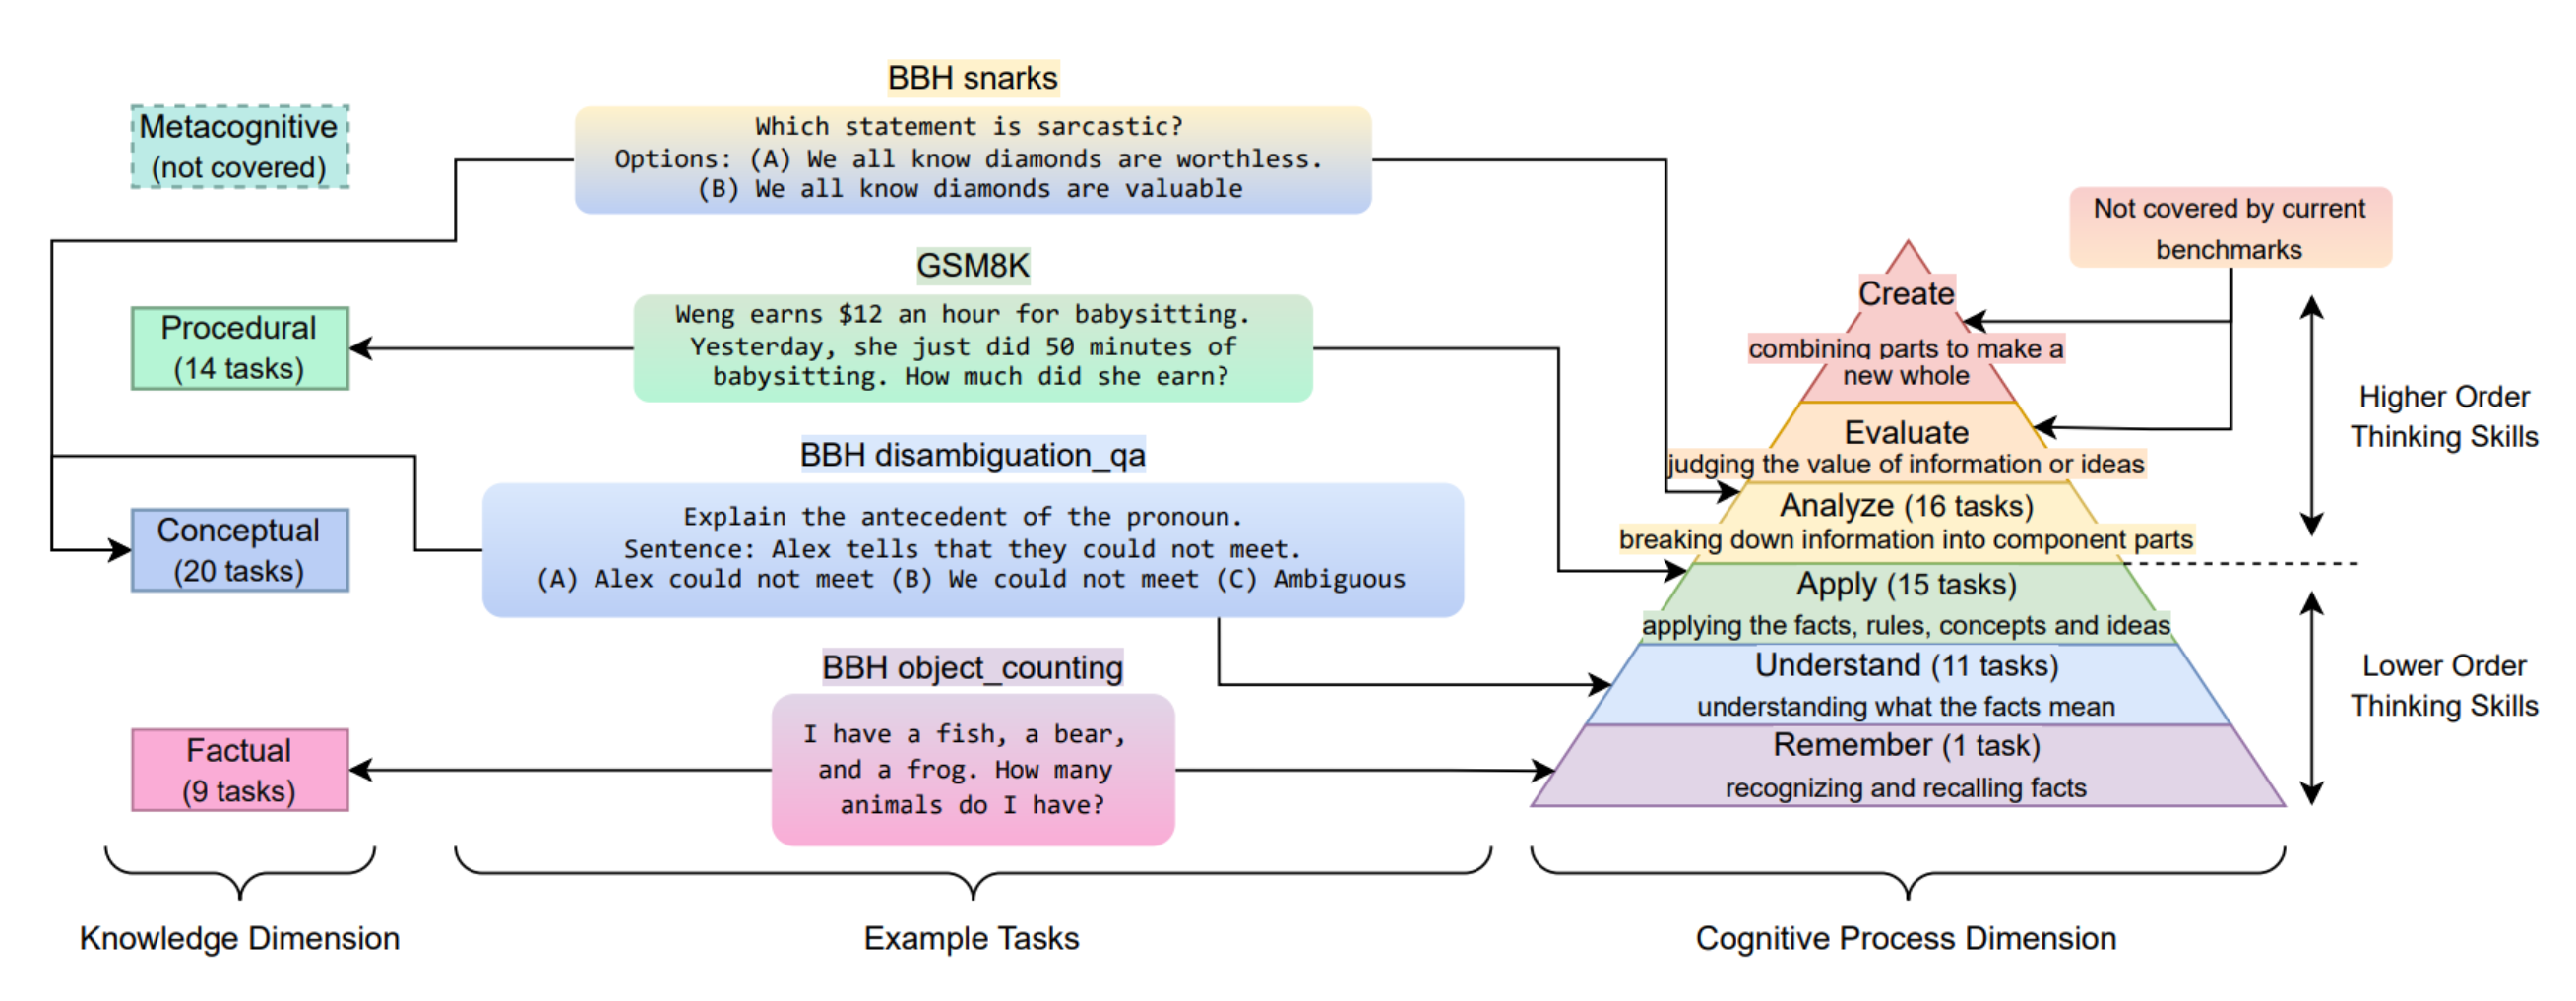

[Revised Bloom's Taxonomy](https://aclanthology.org/2025.coling-main.350/) distinguishes **Remember → Understand → Apply → Analyze → Evaluate → Create**.

**Before running the next cell:** Pick two benchmarks from the table and decide which level each primarily involves. Then reveal the **provisional** mapping and compare your decisions.

The chart counts **our 20 hand-selected representatives**, one per capability section. It does **not** measure the model's capability, the total number of benchmark questions, or the completeness of the full system card.

In [ ]:
# @title B2) Reveal an editable Bloom's Taxonomy mapping

LEVELS = ["Remember", "Understand", "Apply", "Analyze", "Evaluate", "Create"]

# ✏️ update the labels based on what you believe is correct
MY_LABEL_CHANGES = {
    # "GDPval-AA": "Evaluate",
    # "SWE-bench Verified": "Apply",
}

In [ ]:
import matplotlib.pyplot as plt

coverage_B = report_df.copy()
coverage_B["your adjusted label"] = coverage_B.apply(
    lambda row: MY_LABEL_CHANGES.get(row["benchmark"], row["provisional Bloom level"]),
    axis=1,
)
coverage_B[["benchmark", "provisional Bloom level", "plausible alternative", "your adjusted label"]]

In [ ]:
counts_B = coverage_B["your adjusted label"].value_counts().reindex(LEVELS, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(counts_B.index, counts_B.values)
ax.set_ylabel("Representative evaluation families")
ax.set_title("Overview of the benchmark balance")
ax.set_ylim(0, max(1, counts_B.max()) + 1)
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()
print("\nCounts:", counts_B.to_dict())

What does this tell us? Is the evaluation of the model completely useless? What can we do to improve/fix it?

### B3) Evidence → Claims: what does this establish?

Now compare three *illustrative statements* about the evaluation evidence (they are **not direct quotations from Anthropic**):

**Claim 1 — Specific:** “The report presents evaluation evidence about the model's performance on coding, interactive tool use, reasoning, and other identified tasks, under their documented protocols.”

**Claim 2 — General:** “The reported evaluations prove the model will be reliable on **all** open-ended NLG tasks for **all** users.”

**Claim 3 — Relative to purpose:** “This is a balanced evaluation selection **for my intended application**.”

**Your task:** Decide which you can support, which you would qualify, and what *additional* evidence is needed. In particular: **balanced for whom, for which tasks, and for which claims?**

In [ ]:
# @title B3) Your technical-report audit — choose and defend a claim
# ✏️ set your labels here
CLAIM_1 = "UNDECIDED"  # SUPPORTED / QUALIFY / NOT_ESTABLISHED
CLAIM_2 = "UNDECIDED"  # SUPPORTED / QUALIFY / NOT_ESTABLISHED
CLAIM_3 = "UNDECIDED"  # SUPPORTED / QUALIFY / NOT_ESTABLISHED

# ✏️ Name a target application, an evaluation gap for THAT application,
# and a concrete additional task/judge/evidence source.
TARGET_APPLICATION = ""  # e.g. "explanations for non-expert readers"
ADDITIONAL_EVIDENCE = ""  # e.g. "target users answer comprehension questions after reading outputs"

In [ ]:
choices = {"SUPPORTED", "QUALIFY", "NOT_ESTABLISHED", "UNDECIDED"}
for name, judgment in {"Claim 1": CLAIM_1, "Claim 2": CLAIM_2, "Claim 3": CLAIM_3}.items():
    if judgment not in choices:
        raise ValueError(f"{name}: choose one of {sorted(choices)}")
    print(f"{name}: {judgment}")

print("Application:", TARGET_APPLICATION or "[specify the intended use]")
print("Additional evidence:", ADDITIONAL_EVIDENCE or "[name a concrete evaluation]")
print("\nNeither a favorable nor an unfavorable verdict is preprogrammed.")
print("A missing item in THIS inventory does not prove it is absent from the full report.")

**Reflect:** Which choices belong to the *model developer*, which to a *benchmark author*, and which to *you as someone making a capability claim*? A Bloom map is a diagnostic lens, not a score for how "good" the developers' report is. The original system card also includes separate safety and alignment evaluations.

---
## C) Six prompted perspectives, one model, real generated texts

We will load **anonymized experimental outputs**, not the original arguments.
We used the [Dagstuhl-15512-ArgQuality v2 dataset, by Wachsmuth et al. (2017)](doi.org/10.5281/zenodo.3973285). To avoid distributing the dataset we anonymized the generations. You can restore our original prompts by downloading this dataset yourself and running the [deanonymization script](https://github.com/unisg-ics-dsnlp/beyond-leaderboards/blob/public/utils/deanonymize_generations.py).

The repository organizes files by:

- **Prompted perspective:** `communist`, `eco_justice`, `libertarian`, `neo_reactionary`, `populist_nationalist`, `religious_conservative`.
- **Model:** **Claude Sonnet 4.6** is selected by default (for this notebook, you can experiment with the other models).
- **Item and criterion:** one `.txt` file per argument × evaluation dimension × perspective. Matching filenames identify the same item across all six perspectives.
- **Output:** a rating (`1`, `2`, `3`, or `?` for *Cannot judge*) and the model's **written explanation**.

**Run the next cell once.** It checks out the selected model's output folders from the public GitHub repository and parses **every available text file** across the six perspectives.

In [ ]:
# @title C) Load one model's complete outputs across all six prompted perspectives
import os, re, subprocess
from pathlib import Path
import pandas as pd

GITHUB_REPO = "https://github.com/unisg-ics-dsnlp/beyond-leaderboards.git"
BRANCH = "public"
MODEL_FOLDER = "anthropic__claude-sonnet-4.6"  # you can use the outputs of another model here as well
DATA_FOLDER = "data/generations_anonymized"
PERSPECTIVES = [
    "communist", "eco_justice", "libertarian", "neo_reactionary",
    "populist_nationalist", "religious_conservative"
]
LOCAL_REPO = Path.cwd() / "inlg_beyond_leaderboards_public"

def run_git(args, timeout=240):
    env = os.environ.copy()
    env["GIT_TERMINAL_PROMPT"] = "0"
    result = subprocess.run(args, text=True, capture_output=True, timeout=timeout, env=env)
    if result.returncode != 0:
        raise RuntimeError(
            "GitHub download failed. The repository's ENTIRE visibility must be public, "
            "not merely its branch name. Check GitHub access in an incognito window, "
            "and verify your internet connection.\n"
            + (result.stderr or result.stdout)[-1400:]
        )
    return result.stdout

if not (LOCAL_REPO / ".git").exists():
    print("Fetching public GitHub branch metadata (first run only)...")
    run_git(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
             "--single-branch", "--branch", BRANCH, GITHUB_REPO, str(LOCAL_REPO)])
else:
    print("Reusing the GitHub checkout in this Colab runtime.")

wanted_dirs = [f"{DATA_FOLDER}/{p}/{MODEL_FOLDER}" for p in PERSPECTIVES]
print("Fetching all matching text files for the six perspectives...")
run_git(["git", "-C", str(LOCAL_REPO), "sparse-checkout", "set", "--cone", *wanted_dirs])

# this extracts the ratings. doesn't work perfectly but well enough for the tutorial
RATING_RE = re.compile(r"\brating\s*:\s*([123?])(?=\s|\*|\(|$)", re.I)
ARG_ID_RE = re.compile(r"(arg\d+)$", re.I)
LABEL_TO_RATING = {"low": "1", "medium": "2", "high": "3", "cannot judge": "?"}
FALLBACK_PATTERNS = [
    ("numeric rating/score", re.compile(
        r"\b(?:rating|score)\s*(?::|=|is|of)\s*\**\s*([123?])(?=\s|\W|$)", re.I)),
    ("rated in a sentence", re.compile(
        r"\b(?:rate|rated|rating)\b[^\n]{0,160}?\*{0,2}([123])\s*\(\s*(low|medium|high)\s*\)", re.I)),
    ("number with label", re.compile(
        r"(?<!\w)([123?])\s*\(\s*(low|medium|high|cannot\s+judge)\s*\)", re.I)),
    ("verbal rating/score", re.compile(
        r"\b(?:rating|score)\s*(?::|=|is|of)\s*\**\s*(low|medium|high|cannot\s+judge)\b", re.I)),
    ("bold verbal label", re.compile(
        r"\*\*\s*(low|medium|high)\s+[a-z][a-z _-]{2,60}?\s*\*\*", re.I)),
]


def parse_output(path):
    text = path.read_text(encoding="utf-8", errors="replace")
    sections = re.split(r"(?m)^\s*-{8,}\s*$", text, maxsplit=1)
    if len(sections) != 2:
        return None, "", "no response separator"
    response = sections[1].strip().replace(r"\*", "*")
    lines = response.splitlines()
    # First prefer the explicitly requested 'Rating: 2' output format.
    for i, line in enumerate(lines):
        match = RATING_RE.search(line)
        if match:
            return match.group(1), "\n".join(lines[i+1:]).strip(), "explicit rating"
    # Then accept common free-form variants in the model RESPONSE (not prompt).
    for method, pattern in FALLBACK_PATTERNS:
        match = pattern.search(response)
        if match:
            val = match.group(1).strip().lower()
            return LABEL_TO_RATING.get(val, val), response, method
    return None, response, "unparsed"


records = []
for perspective in PERSPECTIVES:
    directory = LOCAL_REPO / DATA_FOLDER / perspective / MODEL_FOLDER
    if not directory.exists():
        raise RuntimeError(f"Perspective folder not found: {directory}")
    for file in sorted(directory.rglob("*.txt")):
        rating, explanation, method = parse_output(file)
        arg_match = ARG_ID_RE.search(file.stem)
        records.append({
            "perspective": perspective, "model": MODEL_FOLDER,
            "filename": file.name,
            "argument_id": arg_match.group(1) if arg_match else None,
            "rating": rating, "explanation": explanation,
            "parse_method": method,
        })

df = pd.DataFrame(records)
if df.empty:
    raise RuntimeError("No .txt files found. Verify MODEL_FOLDER and GitHub structure.")

# Infer dimension names from the common filename prefix for each argument ID.
prefixes = {}
for arg, frame in df.dropna(subset=["argument_id"]).groupby("argument_id"):
    stems = [re.sub(r"_arg\d+$", "", name.removesuffix(".txt"))
             for name in frame["filename"].unique()]
    prefix = os.path.commonprefix(stems)
    prefixes[arg] = prefix[:prefix.rfind("_")+1] if "_" in prefix else ""

def get_dimension(record):
    stem = re.sub(r"_arg\d+$", "", record["filename"].removesuffix(".txt"))
    prefix = prefixes.get(record["argument_id"], "")
    return stem[len(prefix):] if prefix and stem.startswith(prefix) else "unknown"

df["dimension"] = df.apply(get_dimension, axis=1)

parsed = df["rating"].notna().sum()
numerical = df["rating"].isin(["1", "2", "3"]).sum()
cannot_judge = df["rating"].eq("?").sum()
print(f"Loaded {len(df):,} text files from {df['perspective'].nunique()}/6 perspectives.")
print(f"Parsed ratings: {parsed:,}/{len(df):,} "
      f"({numerical:,} numeric, {cannot_judge:,} 'Cannot judge').")
print(f"Unparsed responses: {len(df) - parsed} (retained as missing, not guessed).")
print("Files by perspective:")
print(df.groupby("perspective").size().to_string())
print("Evaluation dimensions:", ", ".join(sorted(df["dimension"].unique())))


### C1) What does a single score hide?

Run the cell below. It finds a **real argument–dimension record available for all six prompted perspectives**, prioritizing an example where ratings differ. Inspect the complete distribution and compare **excerpts of all six generated explanations**.

> **Question:** If you only reported the mean or the most frequent rating, what aspect of the model's prompt-conditioned behavior would disappear?

Edit `PREFERRED_DIMENSION` if you want a different criterion, and `EXCERPT_CHARACTERS` to show longer or full explanations (`None` means full text).

In [ ]:
# @title C1) Compare the same item across six perspectives (real data)
from collections import Counter

PREFERRED_DIMENSION = "appropriateness"  # ✏️ Choose another listed dimension if desired

In [ ]:
EXCERPT_CHARACTERS = None

# Require one record for EACH of the six perspectives, including '?' values.
complete_keys = (df.groupby("filename")["perspective"].nunique()
                 .loc[lambda s: s == len(PERSPECTIVES)].index)
complete = df[df["filename"].isin(complete_keys)].copy()
if complete.empty:
    raise RuntimeError("No filenames occur in all six perspective folders. Inspect missing folders/filename alignment above.")

# Prefer one of the requested dimension with a high numeric rating spread.
quality = (complete.assign(numeric=pd.to_numeric(complete["rating"], errors="coerce"))
           .groupby(["filename", "dimension"])
           .agg(valid=("numeric", "count"), spread=("numeric", lambda v: v.max()-v.min()),
                distinct=("numeric", "nunique"))
           .reset_index())
quality = quality[quality["valid"] >= 4]
if quality.empty:
    raise RuntimeError("Not enough parsable ratings for a meaningful six-profile comparison.")
quality["preferred"] = quality["dimension"].eq(PREFERRED_DIMENSION).astype(int)
quality = quality.sort_values(["preferred", "distinct", "spread", "valid"], ascending=False)
selected_filename = quality.iloc[0]["filename"]
example = (complete[complete["filename"] == selected_filename]
           .set_index("perspective").reindex(PERSPECTIVES).reset_index())

print("Real record:", selected_filename)
print("Dimension:", example["dimension"].iloc[0])
print("Original argument content: NOT distributed (only its anonymized identifier)")
display(example[["perspective", "rating"]].rename(columns={"rating":"LLM-generated rating"}))
valid = pd.to_numeric(example["rating"], errors="coerce").dropna()
if len(valid):
    counts = Counter(valid.astype(int))
    print("Mean of numeric ratings:", round(valid.mean(), 2), "(excluding '?' or missing)")
    print("Rating counts:", {r: counts.get(r, 0) for r in (1, 2, 3)}, "| Cannot judge / unavailable:", 6-len(valid))

print("\nGenerated explanations (one model, six prompted perspectives):")
for _, r in example.iterrows():
    explanation = r["explanation"] or "[No explanation extracted]"
    if EXCERPT_CHARACTERS is not None and len(explanation) > EXCERPT_CHARACTERS:
        explanation = explanation[:EXCERPT_CHARACTERS].rsplit(" ", 1)[0] + " …"
    print(f"\n{'-'*66}\n{r['perspective'].upper()} · rating {r['rating']}\n{explanation}")

### C2) Can the item-wise majority describe **nobody's complete rating pattern**?

This needs **several different arguments** rated on the **same criterion** by the same model under all six prompts.

The code searches your **real data** for **three or four items** such that:

1. Each item has a **strict majority** rating (at least **4 out of 6** profiles agree).
2. Combining those majorities into an item-wise "gold" vector yields a pattern **none of the six prompted profiles produced in full**.

If a real example exists among the available records, the cell prints it, including the six profile-level vectors. If it does **not** find one, it says so explicitly instead of inventing empirical results.

*This shows that the item-wise majority can be a useful benchmark target while still failing to represent any individual profile's complete pattern.*

In [ ]:
# @title C2) Find a real item-wise majority counterexample (or report none found)
import itertools
from collections import Counter

REQUIRE_SAME_DIMENSION = True
SEARCH_UP_TO_N_ITEMS = 4  # Try 3, then 4 items; fast for ~20 arguments/dimension.

numeric_df = df[df["rating"].isin(["1", "2", "3"])].copy()
numeric_df["rating"] = numeric_df["rating"].astype(int)
complete_files = (numeric_df.groupby("filename")["perspective"].nunique()
                  .loc[lambda s: s == len(PERSPECTIVES)].index)
numeric_df = numeric_df[numeric_df["filename"].isin(complete_files)]

rating_table = numeric_df.pivot(index="filename", columns="perspective", values="rating")
rating_table = rating_table.reindex(columns=PERSPECTIVES)
dimension_map = df.drop_duplicates("filename").set_index("filename")["dimension"]

# Check strict majorities (no ties and no missing/unknown scores).
strict_majority = {}
for filename, row in rating_table.iterrows():
    count = Counter(int(v) for v in row)
    rating, votes = count.most_common(1)[0]
    if votes > len(PERSPECTIVES) / 2:
        strict_majority[filename] = (rating, votes)

all_dimensions = sorted(set(dimension_map.loc[list(strict_majority)]))
ordered_dims = ([PREFERRED_DIMENSION] if PREFERRED_DIMENSION in all_dimensions else []) + [
    d for d in all_dimensions if d != PREFERRED_DIMENSION
]

found = None
for dim in ordered_dims:
    candidates = [name for name in strict_majority if dimension_map[name] == dim]
    candidates.sort(key=lambda name: (rating_table.loc[name].nunique() > 1,
                                      6-strict_majority[name][1]), reverse=True)
    per_item_vectors = {name: tuple(int(x) for x in rating_table.loc[name, PERSPECTIVES])
                        for name in candidates}
    for n_items in range(3, min(SEARCH_UP_TO_N_ITEMS, len(candidates))+1):
        for selected_items in itertools.combinations(candidates, n_items):
            aggregate = tuple(strict_majority[name][0] for name in selected_items)
            profile_rows = list(zip(*(per_item_vectors[name] for name in selected_items)))
            if aggregate not in profile_rows:
                found = (dim, selected_items, aggregate)
                break
        if found:
            break
    if found:
        break

if found:
    dim, selected_items, aggregate = found
    print(f"REAL COUNTEREXAMPLE FOUND · model {MODEL_FOLDER} · dimension '{dim}'")
    print("Each column is a DISTINCT argument. Full arguments not redistributed.")
    compact = pd.DataFrame({
        f"Item {i+1} · {re.search(r'(arg\d+)', name).group(1) if re.search(r'(arg\d+)', name) else name[:10]}":
          [int(rating_table.loc[name, p]) for p in PERSPECTIVES]
        for i, name in enumerate(selected_items)
    }, index=PERSPECTIVES)
    compact.loc["ITEM-WISE MAJORITY"] = list(aggregate)
    display(compact)
    print("Majority vote counts:", [f"{strict_majority[name][1]}/6" for name in selected_items])
    print("Does any prompted perspective have this COMPLETE vector?",
          any(tuple(compact.loc[p]) == aggregate for p in PERSPECTIVES))
    print("\nTakeaway: independent majorities can create a vector no single prompted profile produced.")
else:
    print("NO qualifying real counterexample found in the complete, parsed records")
    print("(tried strict majorities across 3–4 items within each inferred dimension).")
    print("This does NOT disprove the phenomenon; it simply wasn't verified in this sample.")
    print("Use the clearly illustrative example in the next optional cell if needed.")

### Joint debrief

- **A:** How did the winner change between brevity, a weighted score, and non-negotiable constraints?
- **B:** Is a benchmark *collection* balanced relative to the claim you want to make? What additional evidence would you request?
- **C:** What gets lost when we collapse prompt-conditioned judgments into a single aggregate?

**Takeaway:** A defensible evaluation needs well-defined **constructs**, relevant **evidence**, justified **judges**, considered **aggregation**, and appropriately scoped **claims**.

**Sources:** [Claude Sonnet 4.6 System Card](https://www-cdn.anthropic.com/78073f739564e986ff3e28522761a7a0b4484f84.pdf) · [Huber & Niklaus, COLING 2025](https://aclanthology.org/2025.coling-main.350/) · [Anonymized perspective-conditioned outputs](https://github.com/unisg-ics-dsnlp/beyond-leaderboards/tree/public/data/generations_anonymized).